# Do CV-parser errors reach the selection? A fairness audit of the Adecco reverse matching

**AI Ethics, Module 2 – Hiring CV Bias** · Francesco Baiocchi, Leonardo Petrilli

## Phase 3 – Do the parser's errors reach the selection? (RQ1)

Phase 2 (`phase2_protocol`) fixed the outcome: a candidate is selected for a job if they are in the top half of the
job's candidates, ranked by score, with ties drawn at random. Here we compare the selection made with the parser's
profile (O) and with the corrected one (C), group by group:

* **3.1** What does the correction change, and for which groups?
* **3.2** Independence: are all groups selected at the same rate?
* **3.3** Separation: does the parser make the same errors (false negatives, false positives) in every group?
* **3.4** Sufficiency: given the parser's decision, is a candidate confirmed by the corrected profile at the same
  rate in every group?
* **3.5** Does the answer hold for a stricter selection, the top 3?
* **3.6** Why the South: are southern pairs closer to the cut, why, and what does it mean for a mitigation?

The groups are the values of the sensitive attributes `Gender`, `Location` and their intersection `group`. Each group
is compared with a reference group, which plays the role of the privileged group in the metrics: `Male`, `NORTH` and
`Male_NORTH`. Adecco's score appears only in 3.2, as the real system: it was computed on the profile P, partly entered
by hand (phase 1, section 1.4), so it cannot show the effect of the parser.

All shares in the tables are percentages.

In [ ]:
%load_ext autoreload
%autoreload 2

import warnings

import matplotlib.pyplot as plt
import polars as pl

%matplotlib inline
warnings.filterwarnings("ignore")

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_hide_column_data_types(True)
pl.Config.set_tbl_hide_dataframe_shape(True)

polars.config.Config

In [ ]:
from hiring_cv_bias.fairness.protocol import (
    SCORES,
    add_outcomes,
    filter_protocol,
    load_pairs,
)

df = add_outcomes(filter_protocol(load_pairs()), SCORES)
print(f"protocol pairs: {df.height:,}, candidates: {df['CANDIDATE_ID'].n_unique():,}")

protocol pairs: 36,760, candidates: 6,510


### 3.1 What the correction changes

We follow the correction in three steps: the candidates, their pairs, and the pairs whose outcome changes.

**Candidates.** For each field read by the parser (licenses, languages, job titles in `experience`), the table counts
the candidates who get at least one item the parser had missed, their share of the 6,510 protocol candidates, and the
items added in all.

In [ ]:
from hiring_cv_bias.config import profile_path
from hiring_cv_bias.fairness.metrics import for_display, profile_corrections

profiles = {v: pl.read_parquet(profile_path(v)) for v in ("O", "C")}
corrections = profile_corrections(
    profiles["O"], profiles["C"], df["CANDIDATE_ID"].unique()
)
display(for_display(corrections))

field,candidates_corrected,share_of_candidates,items_added
"""licenses""",2174,33.4,2174
"""languages""",2675,41.1,4833
"""experience""",3066,47.1,4830


Job titles are corrected for the most candidates (62.1%), then languages (41.1%) and licenses (33.4%). A corrected
candidate gets exactly one license, but more than one language or title on average (4,833 languages for 2,675
candidates, 7,679 titles for 4,041).

**Pairs.** A candidate has one pair per job. For each group, the table gives the share of its pairs where the
correction changes `Card_match`, `Languages_match`, the estimated `Experience` (by more than 0.01) and the score.

In [ ]:
from hiring_cv_bias.fairness.metrics import parser_changes

display(for_display(parser_changes(df)))

attribute,group,pairs,Card_match,Languages_match,Experience,score
"""Gender""","""Female""",17489,9.1,6.8,10.3,25.4
"""Gender""","""Male""",19271,9.4,6.5,13.0,27.5
"""Location""","""NORTH""",29144,9.7,6.6,11.3,26.5
"""Location""","""CENTER""",3300,8.6,7.3,12.4,27.2
"""Location""","""SOUTH""",4316,6.8,6.4,14.0,26.0
"""group""","""Female_NORTH""",13798,9.6,7.2,10.4,25.9
"""group""","""Male_NORTH""",15346,9.8,6.1,12.2,27.1
"""group""","""Female_CENTER""",1669,7.5,5.6,8.9,23.1
"""group""","""Male_CENTER""",1631,9.6,9.0,16.0,31.5
"""group""","""Female_SOUTH""",2022,7.0,5.6,11.4,24.4


A license or a language counts only when the job asks for it (phase 1, section 1.2), so `Card_match` and
`Languages_match` change in at most 9.8% and 9.0% of a group's pairs. The score changes in about one pair in three in
every group, from 29.7% (`Female_SOUTH`) to 37.3% (`Male_CENTER`). The South has fewer `Card_match` changes than the
North (6.8% against 9.7%) and more `Experience` changes (19.5% against 18.0%). This table has no intervals: whether such
differences reach the selection is measured in 3.2 and 3.3.

**Pairs that change outcome.** Now we keep only the pairs whose outcome changes from O to C (`changed_pairs`). The
columns are the same as above, but each share is among these pairs (a pair can have more than one change).
`other` is the share whose score changes only through an `Experience` move of 0.01 or less, and
`score_unchanged` the share whose own score does not change at all.

In [ ]:
from hiring_cv_bias.fairness.metrics import SCORE_CHANGED, outcome_change_sources

display(for_display(outcome_change_sources(df)))
changed = df.filter(pl.col("top_half_O") != pl.col("top_half_C"))
same_score = changed.filter(~SCORE_CHANGED)
print(
    f"pairs whose outcome changes: {changed.height:,} of {df.height:,} "
    f"({changed.height / df.height:.1%})"
)
print(
    f"  with the same score: {same_score.height:,} "
    f"({same_score['top_half_C'].sum()} enter the top half, "
    f"{(~same_score['top_half_C']).sum():,} leave it)"
)
print(f"pairs whose score goes down with C: {(df['score_C'] < df['score_O']).sum()}")

attribute,group,changed_pairs,Card_match,Languages_match,Experience,other,score_unchanged
"""Gender""","""Female""",1374,19.3,11.6,32.5,2.1,45.3
"""Gender""","""Male""",1654,17.1,9.4,39.4,2.2,43.3
"""Location""","""NORTH""",2284,19.0,10.6,35.9,2.1,44.1
"""Location""","""CENTER""",287,13.2,13.6,40.8,2.8,42.5
"""Location""","""SOUTH""",457,16.6,7.7,35.7,2.2,45.7
"""group""","""Female_NORTH""",1038,20.8,12.4,31.9,1.6,44.3
"""group""","""Male_NORTH""",1246,17.5,9.0,39.2,2.4,44.0
"""group""","""Female_CENTER""",108,10.2,14.8,38.9,5.6,45.4
"""group""","""Male_CENTER""",179,15.1,12.8,41.9,1.1,40.8
"""group""","""Female_SOUTH""",228,16.7,6.1,32.5,2.6,49.6


pairs whose outcome changes: 3,028 of 36,760 (8.2%)
  with the same score: 1,339 (0 enter the top half, 1,339 leave it)
pairs whose score goes down with C: 0


The correction changes the outcome of 3,218 pairs, 8.8% of the total. In every group the most common cause is a new
job title (`Experience`, 36.7% to 47.0% of the changed pairs), then a license (10.7% to 19.5%) and a language (5.6% to
14.3%). A few pairs (`other`, 1.1% to 4.2%) move only through an `Experience` change smaller than 0.01: a
shift of the score below 0.02 is enough to pass a competitor with the same or almost the same score.

Four of these pairs in ten change nothing of their own: 1,345 of the 3,218 (37.6% to 47.2% per group) keep the same
score. The correction only adds information, so no score goes down, and all 1,345 leave the top half. They are
candidates overtaken by a competitor of the same job whose CV was corrected: with O they had a place only because the
parser had missed something in that competitor's CV.

### 3.2 Independence: selection rates per group

Independence (statistical parity) asks the selection rate P(D = 1 | A = a) to be the same in every group a, where
D = 1 means selected and A is the sensitive attribute. For each score we compare every group with its reference group
in two ways:

* `spd_<score>`, the statistical parity difference: the group's rate minus the reference rate (0 means parity);
* `di_<score>`, the disparate impact: the group's rate divided by the reference rate (1 means parity).

Rates are computed over pairs, the unit fixed in phase 2: each pair is one decision, so a candidate who appears in
several jobs counts once for each job.

**Intervals.** A group has a few hundred to a few thousand candidates, so its numbers are uncertain. We measure this
with a bootstrap: 1,000 times, we draw the candidates again with replacement (a candidate drawn twice counts twice),
draw the ties again and recompute every number. The 95% interval holds the middle 95% of the 1,000 values. We draw
candidates, not pairs: the pairs of a candidate share the same profile and group, so they are not independent, and
drawing them one by one would count them as separate evidence and make the intervals too narrow. If the interval of an
SPD contains 0, or that of a DI contains 1, the data show no difference.

The figure shows the rates with their intervals; the dashed line is the rate of all pairs. SPD, in percentage
points, and DI, a ratio, are quoted in the text with their intervals.

In [ ]:
from hiring_cv_bias.fairness.metrics import bootstrap, parser_effect, selection_rates

results = bootstrap(
    df,
    {
        "rates": selection_rates,
        "effect": parser_effect,
        "effect_top3": lambda d: parser_effect(d, outcome="top3"),
    },
)

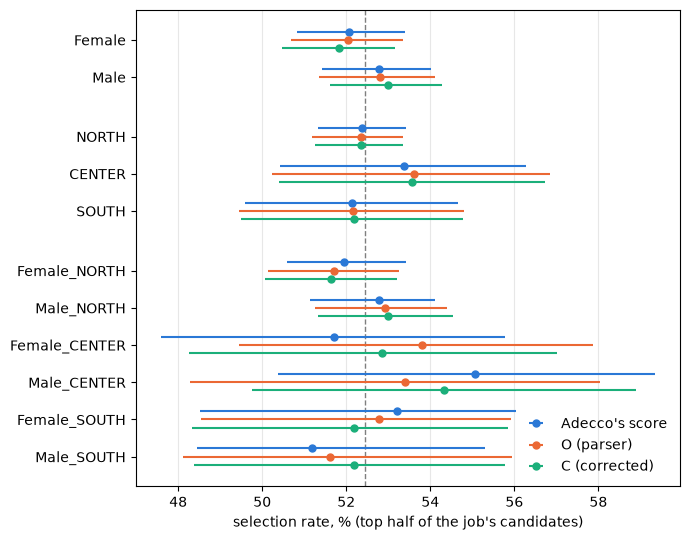

In [ ]:
from hiring_cv_bias.fairness.plots import plot_selection_rates

rates = results["rates"]
plot_selection_rates(rates, overall=df["top_half_O"].mean())
plt.show()

In [ ]:
from hiring_cv_bias.fairness.protocol import COMPARED_VERSIONS

display(for_display(rates, [f"rate_{v}" for v in COMPARED_VERSIONS]))
display(
    for_display(
        rates,
        [f"spd_{v}" for v in COMPARED_VERSIONS],
        ratios=[f"di_{v}" for v in COMPARED_VERSIONS],
    )
)

attribute,group,pairs,rate_adecco,rate_O,rate_C
"""Gender""","""Female""",17489,"""52.1 [50.8, 53.4]""","""52.0 [50.7, 53.3]""","""51.8 [50.5, 53.1]"""
"""Gender""","""Male""",19271,"""52.8 [51.4, 54.0]""","""52.8 [51.4, 54.1]""","""53.0 [51.6, 54.3]"""
"""Location""","""NORTH""",29144,"""52.4 [51.3, 53.4]""","""52.4 [51.2, 53.3]""","""52.4 [51.3, 53.3]"""
"""Location""","""CENTER""",3300,"""53.4 [50.4, 56.3]""","""53.6 [50.2, 56.8]""","""53.6 [50.4, 56.7]"""
"""Location""","""SOUTH""",4316,"""52.1 [49.6, 54.7]""","""52.2 [49.4, 54.8]""","""52.2 [49.5, 54.8]"""
"""group""","""Female_NORTH""",13798,"""51.9 [50.6, 53.4]""","""51.7 [50.1, 53.3]""","""51.6 [50.1, 53.2]"""
"""group""","""Male_NORTH""",15346,"""52.8 [51.1, 54.1]""","""52.9 [51.3, 54.4]""","""53.0 [51.3, 54.5]"""
"""group""","""Female_CENTER""",1669,"""51.7 [47.6, 55.8]""","""53.8 [49.5, 57.9]""","""52.8 [48.3, 57.0]"""
"""group""","""Male_CENTER""",1631,"""55.1 [50.4, 59.4]""","""53.4 [48.3, 58.0]""","""54.3 [49.8, 58.9]"""
"""group""","""Female_SOUTH""",2022,"""53.2 [48.5, 56.0]""","""52.8 [48.6, 55.9]""","""52.2 [48.3, 55.9]"""


attribute,group,pairs,spd_adecco,spd_O,spd_C,di_adecco,di_O,di_C
"""Gender""","""Female""",17489,"""-0.7 [-2.6, 1.2]""","""-0.8 [-2.8, 1.1]""","""-1.2 [-3.2, 0.8]""","""0.99 [0.95, 1.02]""","""0.99 [0.95, 1.02]""","""0.98 [0.94, 1.02]"""
"""Gender""","""Male""",19271,"""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""1.00 [1.00, 1.00]""","""1.00 [1.00, 1.00]""","""1.00 [1.00, 1.00]"""
"""Location""","""NORTH""",29144,"""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""1.00 [1.00, 1.00]""","""1.00 [1.00, 1.00]""","""1.00 [1.00, 1.00]"""
"""Location""","""CENTER""",3300,"""1.0 [-2.0, 4.2]""","""1.3 [-2.3, 4.7]""","""1.2 [-2.1, 4.5]""","""1.02 [0.96, 1.08]""","""1.02 [0.96, 1.09]""","""1.02 [0.96, 1.09]"""
"""Location""","""SOUTH""",4316,"""-0.2 [-2.9, 2.5]""","""-0.2 [-3.1, 2.8]""","""-0.2 [-3.1, 2.7]""","""1.00 [0.94, 1.05]""","""1.00 [0.94, 1.05]""","""1.00 [0.94, 1.05]"""
"""group""","""Female_NORTH""",13798,"""-0.8 [-2.7, 1.4]""","""-1.2 [-3.4, 1.1]""","""-1.3 [-3.6, 0.8]""","""0.98 [0.95, 1.03]""","""0.98 [0.94, 1.02]""","""0.97 [0.93, 1.02]"""
"""group""","""Male_NORTH""",15346,"""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""1.00 [1.00, 1.00]""","""1.00 [1.00, 1.00]""","""1.00 [1.00, 1.00]"""
"""group""","""Female_CENTER""",1669,"""-1.1 [-5.2, 3.5]""","""0.9 [-3.8, 5.5]""","""-0.1 [-4.8, 4.3]""","""0.98 [0.90, 1.07]""","""1.02 [0.93, 1.11]""","""1.00 [0.91, 1.08]"""
"""group""","""Male_CENTER""",1631,"""2.3 [-2.6, 6.9]""","""0.5 [-4.5, 5.4]""","""1.3 [-3.6, 6.0]""","""1.04 [0.95, 1.12]""","""1.01 [0.91, 1.10]""","""1.03 [0.93, 1.11]"""
"""group""","""Female_SOUTH""",2022,"""0.4 [-4.1, 3.5]""","""-0.1 [-4.6, 3.3]""","""-0.8 [-4.9, 3.1]""","""1.01 [0.92, 1.07]""","""1.00 [0.91, 1.06]""","""0.98 [0.91, 1.06]"""


Every SPD is between −1.6 and +2.3 points and every DI between 0.97 and 1.04, with Adecco's score, with O and with C;
every SPD interval contains 0 and every DI interval contains 1. Women are selected 0.7 points less often than men
with Adecco's score, 0.8 with O and 1.1 with C (DI 0.99, 0.99 and 0.98). The lowest bound of any DI is 0.90, well
above the 0.8 of the four-fifths rule. The data show no violation of independence, before or after the correction.

### 3.3 Separation: the parser's errors per group

To measure the parser's errors we take the outcome with the corrected profile as the label Y and the outcome with the
parser's profile as the decision D. C is not the truth: it holds what our extractors recovered from the CV text, so
the errors below are errors of O relative to C.

* **False negative** (D = 0, Y = 1): a pair selected with C that O leaves out. `fnr` = P(D = 0 | Y = 1, A = a).
* **False positive** (D = 1, Y = 0): a pair that O selects and C does not. `fpr` = P(D = 1 | Y = 0, A = a).

Separation (equalized odds) asks both rates to be the same in every group: `fnr_diff` and `fpr_diff` are the gaps from
the reference group. `rate_change`, the rate with C minus the rate with O, tells whether a group gains places when the
parser is corrected. Every job selects the same number of candidates with O and with C, so a group can have
`rate_change` = 0 and still many errors, if it has as many false negatives as false positives. The figure shows
`rate_change` and the two gaps; the dashed line is 0.

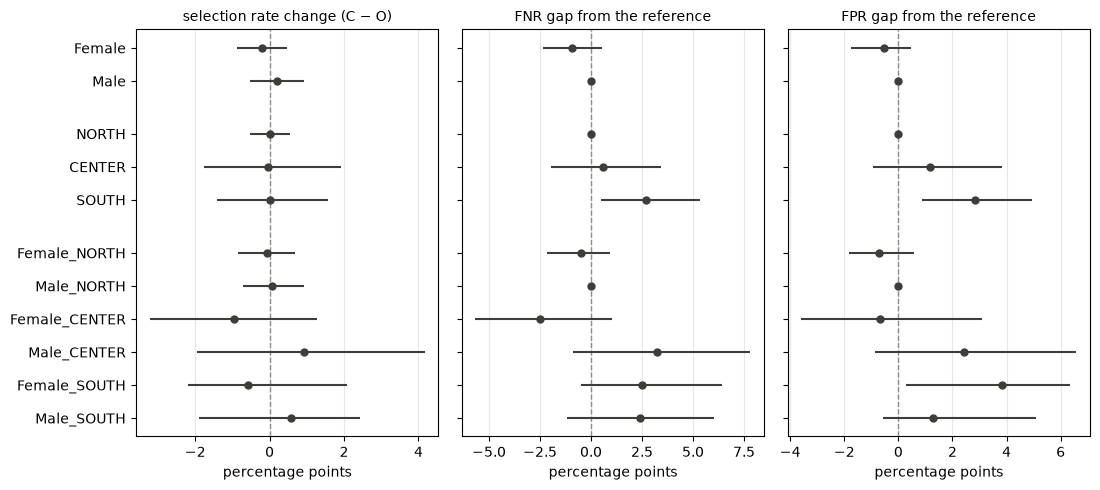

In [ ]:
from hiring_cv_bias.fairness.plots import plot_parser_effect

effect = results["effect"]
plot_parser_effect(effect)
plt.show()

In [ ]:
display(for_display(effect, ["rate_change", "fnr", "fpr", "fnr_diff", "fpr_diff"]))

attribute,group,pairs,rate_change,fnr,fpr,fnr_diff,fpr_diff
"""Gender""","""Female""",17489,"""-0.2 [-0.9, 0.5]""","""7.4 [6.3, 8.4]""","""8.4 [7.5, 9.1]""","""-0.9 [-2.4, 0.5]""","""-0.5 [-1.7, 0.5]"""
"""Gender""","""Male""",19271,"""0.2 [-0.5, 0.9]""","""8.3 [7.1, 9.3]""","""8.9 [8.1, 9.7]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""NORTH""",29144,"""0.0 [-0.5, 0.6]""","""7.5 [6.7, 8.3]""","""8.2 [7.6, 8.8]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""CENTER""",3300,"""0.0 [-1.8, 1.9]""","""8.1 [5.7, 10.9]""","""9.4 [7.4, 11.8]""","""0.6 [-2.0, 3.4]""","""1.2 [-0.9, 3.8]"""
"""Location""","""SOUTH""",4316,"""0.0 [-1.4, 1.6]""","""10.2 [8.1, 12.7]""","""11.0 [9.1, 13.1]""","""2.7 [0.5, 5.4]""","""2.8 [0.9, 5.0]"""
"""group""","""Female_NORTH""",13798,"""-0.1 [-0.8, 0.7]""","""7.2 [6.1, 8.3]""","""7.9 [7.0, 8.6]""","""-0.5 [-2.2, 0.9]""","""-0.7 [-1.8, 0.6]"""
"""group""","""Male_NORTH""",15346,"""0.1 [-0.7, 0.9]""","""7.7 [6.5, 9.0]""","""8.6 [7.6, 9.3]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""group""","""Female_CENTER""",1669,"""-1.0 [-3.2, 1.3]""","""5.2 [2.5, 8.7]""","""7.9 [5.1, 11.3]""","""-2.5 [-5.7, 1.0]""","""-0.7 [-3.6, 3.1]"""
"""group""","""Male_CENTER""",1631,"""0.9 [-2.0, 4.2]""","""10.9 [6.9, 15.3]""","""11.0 [7.7, 15.0]""","""3.2 [-0.9, 7.8]""","""2.4 [-0.9, 6.6]"""
"""group""","""Female_SOUTH""",2022,"""-0.6 [-2.2, 2.1]""","""10.2 [7.5, 13.8]""","""12.4 [9.0, 14.7]""","""2.5 [-0.5, 6.4]""","""3.8 [0.3, 6.4]"""


**Places.** Every `rate_change` interval contains 0; the largest values are −1.3 points for `Female_CENTER` and +1.2
for `Male_CENTER`. Correcting the parser does not move places from one group to another.

**Errors.** The South is the only area where the parser's errors differ from the North, and in both directions:

* FNR: O leaves out 10.9% of the southern pairs selected with C, against 8.0% in the North (gap 2.9 points);
* FPR: O selects 11.7% of the southern pairs not selected with C, against 8.8% (gap 3.0).

False negatives and false positives cancel in the count, so `rate_change` is 0, but more southern decisions are wrong.
Among the six intersectional groups, the only gap whose interval excludes 0 is the FPR of `Female_SOUTH`: 13.4%
against 9.1% for `Male_NORTH` (gap 4.2), so equalized odds fails for this group too, through
the FPR. Between women and men there is no gap.

### 3.4 Sufficiency: how reliable the parser's decision is, per group

Sufficiency (calibration) conditions the other way round: it fixes the decision and asks whether the true outcome
depends on the group. For a binary decision it is two equalities, the positive predictive value P(Y = 1 | D = 1, A = a),
the share of the pairs O selects that C confirms (`ppv`), and the negative predictive value P(Y = 0 | D = 0, A = a), the
share of the pairs O rejects that C confirms (`npv`). Separation compares the rows of the confusion matrix (given the
true outcome, how the parser decides), sufficiency its columns (given the parser's decision, how often it is right).
The figure shows the gaps of the two values from the reference group (`ppv_diff`, `npv_diff`); the dashed line is 0.

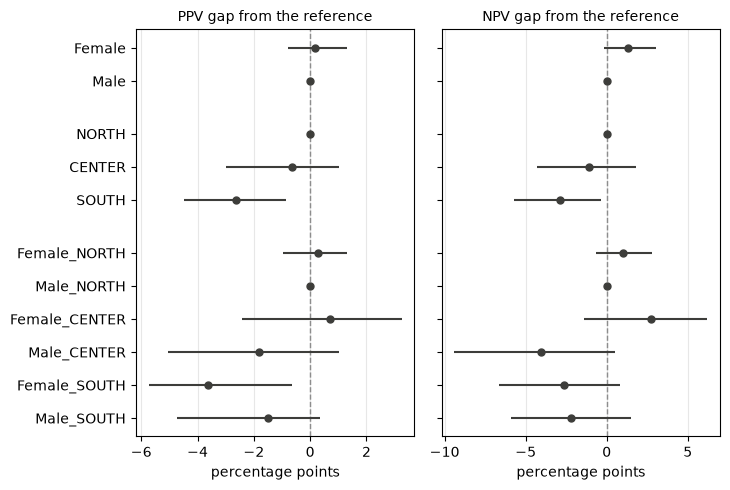

In [ ]:
from hiring_cv_bias.fairness.plots import SUFFICIENCY_PANELS

plot_parser_effect(effect, SUFFICIENCY_PANELS)
plt.show()

Both predictive values are above 86% in every group: when the parser's profile selects a candidate, the corrected one
confirms it about nine times in ten, and the same for a rejection.

The South is again the only area that differs from the North, and on both sides: O's selections are confirmed by C in
89.2% of the southern pairs against 92.0% in the North (gap −2.8), its rejections in 88.1% against 91.2% (gap −3.1), and
both intervals exclude 0. Among the intersectional groups, women from the South have a lower PPV (87.9% against 91.9%
for `Male_NORTH`, gap −4.0); their NPV gap (−3.3) and every other gap include 0. Between women and men there is no gap.

So the South fails all three criteria: it is selected at the same rate (3.2), but O's decisions on southern candidates
are wrong more often in both directions (3.3) and, read from the decision's side, confirmed less often (3.4).

### 3.5 The same with the top 3

A stricter selection: the first three candidates of every job. The table repeats `rate_change`, `fnr_diff` and
`fpr_diff` of 3.3 and `ppv_diff` and `npv_diff` of 3.4 with `top3` as the outcome.

In [ ]:
display(for_display(effect, ["ppv", "npv", "ppv_diff", "npv_diff"]))

attribute,group,pairs,ppv,npv,ppv_diff,npv_diff
"""Gender""","""Female""",17489,"""92.2 [91.6, 93.1]""","""92.0 [91.0, 93.1]""","""0.2 [-0.8, 1.3]""","""1.3 [-0.2, 3.0]"""
"""Gender""","""Male""",19271,"""92.1 [91.3, 92.8]""","""90.7 [89.5, 91.9]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""NORTH""",29144,"""92.5 [92.0, 93.1]""","""91.8 [90.9, 92.7]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""CENTER""",3300,"""91.9 [89.7, 93.5]""","""90.7 [87.6, 93.4]""","""-0.7 [-3.0, 1.0]""","""-1.1 [-4.3, 1.8]"""
"""Location""","""SOUTH""",4316,"""89.9 [88.1, 91.5]""","""88.9 [86.3, 91.2]""","""-2.6 [-4.5, -0.9]""","""-2.9 [-5.7, -0.4]"""
"""group""","""Female_NORTH""",13798,"""92.7 [91.9, 93.5]""","""92.3 [91.1, 93.5]""","""0.3 [-1.0, 1.3]""","""1.0 [-0.7, 2.8]"""
"""group""","""Male_NORTH""",15346,"""92.4 [91.7, 93.2]""","""91.3 [89.9, 92.6]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""group""","""Female_CENTER""",1669,"""93.1 [90.2, 95.5]""","""94.0 [90.1, 97.0]""","""0.7 [-2.4, 3.3]""","""2.7 [-1.4, 6.2]"""
"""group""","""Male_CENTER""",1631,"""90.6 [87.4, 93.3]""","""87.2 [82.1, 91.7]""","""-1.8 [-5.1, 1.0]""","""-4.1 [-9.4, 0.5]"""
"""group""","""Female_SOUTH""",2022,"""88.8 [86.8, 91.7]""","""88.7 [85.0, 91.8]""","""-3.6 [-5.7, -0.6]""","""-2.6 [-6.6, 0.8]"""


Both predictive values are above 87% in every group: when the parser's profile selects a candidate, the corrected one
confirms it about nine times in ten, and the same for a rejection.

The South is again the only area that differs from the North, and on both sides: O's selections are confirmed by C in
89.9% of the southern pairs against 92.5% in the North (gap −2.6), its rejections in 88.9% against 91.8% (gap −2.9), and
both intervals exclude 0. Among the intersectional groups, women from the South have a lower PPV (88.8% against 92.4%
for `Male_NORTH`, gap −3.6); their NPV gap (−2.6) and every other gap include 0. Between women and men there is no gap.

So the South fails all three criteria: it is selected at the same rate (3.2), but O's decisions on southern candidates
are wrong more often in both directions (3.3) and, read from the decision's side, confirmed less often (3.4).

### 3.5 The same with the top 3

A stricter selection: the first three candidates of every job. The table repeats `rate_change`, `fnr_diff` and
`fpr_diff` of 3.3 and `ppv_diff` and `npv_diff` of 3.4 with `top3` as the outcome.

In [ ]:
display(
    for_display(
        results["effect_top3"],
        ["rate_change", "fnr_diff", "fpr_diff", "ppv_diff", "npv_diff"],
    )
)

attribute,group,pairs,rate_change,fnr_diff,fpr_diff,ppv_diff,npv_diff
"""Gender""","""Female""",17489,"""0.3 [-0.3, 0.9]""","""-0.5 [-2.6, 2.0]""","""-0.8 [-1.6, -0.1]""","""2.3 [0.4, 4.0]""","""0.1 [-0.9, 1.0]"""
"""Gender""","""Male""",19271,"""-0.3 [-0.9, 0.4]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""NORTH""",29144,"""0.0 [-0.5, 0.4]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""CENTER""",3300,"""0.0 [-1.9, 1.8]""","""1.9 [-2.4, 6.6]""","""2.0 [0.5, 3.9]""","""-1.9 [-5.5, 1.3]""","""-2.0 [-4.2, 0.1]"""
"""Location""","""SOUTH""",4316,"""0.0 [-1.3, 1.2]""","""4.4 [0.3, 8.3]""","""0.4 [-0.5, 1.5]""","""-4.5 [-7.8, -1.6]""","""-0.4 [-1.8, 0.9]"""
"""group""","""Female_NORTH""",13798,"""0.3 [-0.3, 1.0]""","""0.4 [-2.1, 2.9]""","""-0.6 [-1.4, 0.2]""","""1.7 [-0.4, 3.6]""","""-0.2 [-1.2, 0.7]"""
"""group""","""Male_NORTH""",15346,"""-0.3 [-0.9, 0.3]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""group""","""Female_CENTER""",1669,"""-0.2 [-2.1, 2.1]""","""-2.2 [-6.7, 3.6]""","""0.1 [-1.7, 2.0]""","""2.5 [-1.3, 6.2]""","""-0.1 [-3.1, 2.0]"""
"""group""","""Male_CENTER""",1631,"""0.2 [-3.2, 3.6]""","""6.4 [-0.6, 13.7]""","""3.3 [0.8, 6.8]""","""-4.7 [-11.3, 0.0]""","""-4.0 [-7.8, -0.9]"""
"""group""","""Female_SOUTH""",2022,"""0.3 [-1.4, 2.2]""","""5.1 [-0.6, 11.3]""","""-0.1 [-1.5, 1.4]""","""-2.9 [-7.8, 1.3]""","""-0.7 [-2.9, 1.2]"""


Every `rate_change` interval still contains 0, and the higher FNR of the South remains: 4.6 points more than the North.
The higher FPR does not (0.5 points). Four separation gaps exclude 0 here but not in 3.3: the FPR is higher for `CENTER` (2.4 points) and `Male_CENTER` (3.3) and lower for women (−0.7), and the FNR is
higher for `Female_SOUTH` (5.6); the FNR gap of `Male_CENTER` (7.1) has 0 as its lower bound.

For sufficiency, the lower PPV of the South remains (−4.7 points) while its NPV gap does not (−0.4): with three places
per job, the pairs O rejects are almost all confirmed in every group, and the groups differ only on the pairs it selects.
Four sufficiency gaps exclude 0 here but not in 3.4: the NPV is lower for `CENTER` (−2.4) and `Male_CENTER` (−4.6), the
PPV is higher for women (+2.0) and lower for `Male_SOUTH` (−4.6); the lower PPV of `Female_SOUTH` seen in 3.4 does not
hold here (−3.1).

**Many comparisons.** 3.3 to 3.5 hold 64 gaps (8 groups × 4 rates × 2 outcomes). At the 95% level, about three
of them would exclude 0 by chance alone. So a gap seen with only one outcome is weak evidence; the ones seen with both are
the higher FNR and the lower PPV of the South.

### 3.6 Why the South: the lists, not the readers

3.3 and 3.4 show that O's decisions on southern pairs are wrong more often, in both directions. Yet 3.1 shows that
the correction touches southern and northern pairs alike: the score changes for 26.0% of the South's pairs and 26.5%
of the North's. So the South does not get more corrections; its corrections flip more outcomes.

**The claim of this section.** An outcome is a place in the job's list, and a change of score flips it only when the
pair is closer to the cut than the change is large. Southern pairs are closer to the cut, because many southern jobs
require no skill that separates the candidates. In those lists any noise, not only the parser's, flips more
decisions. This is the robustness side of RQ1: how stable the decisions are under the noise of the profile,
group by group.

**One metric.** The whole section uses the error rate: the share of a group's pairs whose outcome differs between O
and C. It counts the false negatives and the false positives of 3.3 together, over all the pairs. The gap is the
South's rate minus the North's. The intervals come from the same bootstrap as 3.2, run once more here.

#### 3.6.1 Are southern pairs closer to the cut?

The margin of a pair is the distance between its score under O and the score of the last selected candidate of its
list (the cutoff score). The table gives, per region, the median margin, the share of pairs within 0.1 points of the
cut, and the share of pairs whose outcome Adecco's own score leaves to the tie-break (`draw_adecco`: a tie across the
cut).

In [ ]:
from hiring_cv_bias.config import REVERSE_MATCHING_PATH
from hiring_cv_bias.fairness.robustness import (
    error_by_class,
    list_class,
    margin_table,
    standardized_error,
)
from hiring_cv_bias.reverse_matching.components import job_requirements
from hiring_cv_bias.utils import load_excel_sheets

jobs_req = job_requirements(load_excel_sheets(REVERSE_MATCHING_PATH, ["Jobs"])["Jobs"])
df = df.join(
    jobs_req.select(
        "Job_id", (pl.col("req_skills").list.len() > 0).alias("skills_required")
    ),
    on="Job_id",
    how="left",
).with_columns(list_class(pl.col("skills_required"), "O").alias("class"))
robust = bootstrap(
    df,
    {
        "standardized": lambda d: standardized_error(d, "Location", "NORTH"),
        "by_class": lambda d: error_by_class(d, pl.col("class")),
    },
)
display(
    for_display(
        margin_table(df, ["Location"], draws=("adecco",)), ratios=["margin_median"]
    )
)

attribute,group,pairs,margin_median,within_0.1,draw_adecco
"""Location""","""NORTH""",29144,0.35,31.5,19.5
"""Location""","""CENTER""",3300,0.3,34.9,21.0
"""Location""","""SOUTH""",4316,0.16,42.6,29.1


The median margin is 0.16 points in the South against 0.35 in the North, and 42.6% of the southern pairs are
within 0.1 points of the cut, against 31.5%. Adecco's own score ties 29.1% of the southern pairs across the cut,
against 19.5%: the real system draws lots for three southern pairs in ten. The Center is close to the North.

#### 3.6.2 Would the gap remain if southern pairs were as far from the cut as northern ones?

We split the pairs into five bands of margin: a tie, up to 0.1, 0.1 to 0.3, 0.3 to 0.6, above 0.6. `error_std` takes
the region's error rate in each band and weights it by the share of northern pairs in that band: it is the error
rate the region would have with the North's margins. `gap` and `gap_std` are the gaps of `error` and `error_std` from
the North.

In [ ]:
display(for_display(robust["standardized"]))

attribute,group,pairs,error,error_std,gap,gap_std
"""Location""","""CENTER""",3300,"""8.7 [7.1, 10.5]""","""8.3 [6.6, 10.2]""","""0.9 [-0.8, 2.8]""","""0.5 [-1.2, 2.4]"""
"""Location""","""NORTH""",29144,"""7.8 [7.3, 8.3]""","""7.8 [7.3, 8.3]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""SOUTH""",4316,"""10.6 [9.1, 12.1]""","""9.3 [8.1, 10.8]""","""2.8 [1.3, 4.4]""","""1.5 [0.1, 3.1]"""


About half of the gap goes. The South's error rate is 10.6% against 7.8% in the North (gap 2.8 points, [1.3, 4.4]);
with the North's margins it would be 9.3% (gap 1.5). The interval of this second gap, [0.1, 3.1], only just excludes
0, so the half that remains at equal margin is weak evidence. A candidate cause is the estimated `Experience`, which
the correction changes a little more often in the South (14.0% of the pairs against 11.3%, 3.1).

#### 3.6.3 Why are southern pairs closer to the cut?

The score is a sum of seven terms (phase 1). `Experience` is continuous but confined between 0.8 and 1 for a
candidate with titles, and most other terms take two or three values. The term that spreads the scores is
`match_skills`, with weight 1: the share of the job's required skills that the candidate holds. It reads the
`skills` field of Adecco's profile, which no extractor touches. When the job requires no skill, or requires skills
that give every candidate of the list the same value (for example, nobody has them), `match_skills` cannot separate
the candidates and the scores pile up near the cut.

We split the lists into three classes:

* `none required`: the job requires no skill;
* `required, same for all`: the job requires skills, but every candidate of the list gets the same `match_skills`;
* `required, discriminate`: the required skills give the candidates different values.

The first table counts the lists of each class per region, with the median margin. The second gives the error rate
of the North and of the South in each class, and the gap (`pairs` counts the South's pairs). The figure shows the same error rates with their 95%
intervals.

In [ ]:
from hiring_cv_bias.fairness.robustness import list_classes_table

display(
    for_display(
        list_classes_table(df, pl.col("class"), "O"),
        ["share_of_lists"],
        ratios=["margin_median"],
    )
)
display(for_display(robust["by_class"]))

Location,class,lists,share_of_lists,pairs,margin_median
"""CENTER""","""none required""",185,53.2,1717,0.25
"""CENTER""","""required, discriminate""",121,34.8,1227,0.38
"""CENTER""","""required, same for all""",42,12.1,356,0.18
"""NORTH""","""none required""",1117,41.9,11197,0.3
"""NORTH""","""required, discriminate""",1181,44.3,14419,0.4
"""NORTH""","""required, same for all""",366,13.7,3528,0.21
"""SOUTH""","""none required""",199,59.9,2653,0.1
"""SOUTH""","""required, discriminate""",83,25.0,1162,0.41
"""SOUTH""","""required, same for all""",50,15.1,501,0.08


class,pairs,error_north,error_south,gap
"""none required""",2653,"""7.8 [7.0, 8.4]""","""11.6 [10.1, 13.7]""","""3.8 [2.2, 6.2]"""
"""required, same for all""",501,"""4.6 [3.8, 5.5]""","""9.2 [5.2, 11.8]""","""4.5 [0.5, 7.4]"""
"""required, discriminate""",1162,"""8.6 [7.9, 9.4]""","""9.0 [6.6, 11.2]""","""0.3 [-2.2, 2.7]"""


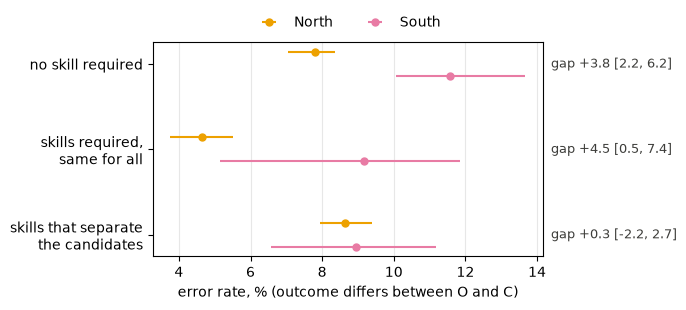

In [ ]:
from hiring_cv_bias.fairness.plots import plot_error_by_class

plot_error_by_class(robust["by_class"])
plt.show()

The South has more lists where the score cannot separate the candidates. Six southern lists in ten (59.9%) belong
to a job that requires no skill, against 41.9% in the North; only one in four (25.0%) has required skills that
separate the candidates, against 44.3%. In these last lists the margins are the same in both regions (0.41 and
0.40); in the others the South's are much smaller (0.10 against 0.30 where nothing is required, 0.08 against 0.21
where the skills give everyone the same value).

The gap follows the classes. Where the skills separate the candidates, the South's error rate is the North's
(9.0% against 8.6%, gap 0.3 points, [−2.2, 2.7]). Where the job requires nothing, it is 11.6% against 7.8% (gap 3.8 points, [2.2, 6.2]). Where the skills give everyone the
same value the gap is as large (4.5 points, [0.5, 7.4]), but on only 501 southern pairs, so its interval is wide.

#### 3.6.4 Does any noise do this, or only the parser?

If the gap comes from the lists, the same noise should flip more southern decisions, with no parser involved. We
add Gaussian noise to the estimated `Experience` of every pair (standard deviation 0.05 or 0.10, kept within 0 and
1), recompute the score with the formula, re-rank every list with the same tie-break and count the pairs whose
outcome changes, averaged over 20 draws. The noise is the same for everyone. The table gives the share of flipped
decisions per class, for the North and the South (`north_0.05` is the North with noise 0.05). 

In [ ]:
from hiring_cv_bias.fairness.robustness import LIST_CLASSES, perturbation_flips

flips = (
    perturbation_flips(df, by=("Location", "class"))
    .filter(pl.col("Location").is_in(["NORTH", "SOUTH"]))
    .with_columns(
        pl.format(
            "{}_{}", pl.col("Location").str.to_lowercase(), pl.col("sigma")
        ).alias("region_noise")
    )
    .pivot(on="region_noise", index="class", values="flipped")
    .sort(
        pl.col("class").replace_strict(
            {c: i for i, c in enumerate(LIST_CLASSES)}, return_dtype=pl.Int64
        )
    )
)
display(for_display(flips))

class,north_0.05,south_0.05,north_0.1,south_0.1
"""none required""",11.2,17.4,15.3,21.7
"""required, same for all""",12.9,17.4,17.0,22.0
"""required, discriminate""",7.1,6.8,10.8,9.8


With noise 0.05, 17.4% of the southern decisions flip in the lists without required skills, against 11.2% of
the northern ones, and 17.4% against 12.9% where the skills give everyone the same value. Where the skills separate
the candidates the South is as stable as the North (6.8% against 7.1%). With noise 0.10 the pattern is the same
(21.7% against 15.3%, 22.0% against 17.0%, 9.8% against 10.8%). The gap is a property of the lists: the same noise
flips more southern decisions, and only where the score has nothing to separate the candidates with.

#### 3.6.5 What could a mitigation do?

The harm found in RQ1 is a gap in separation and sufficiency, not in independence, and it has two parts: the noise
the parser adds, and the lists in which any noise turns into a wrong decision.

* *Correct the parser's output.* That is C. It removes the parser's noise, but the lists stay as they are: any other
  noise (the `Experience` estimate, a future extractor's errors) would again flip more southern decisions (3.6.4).
* *Change the matcher.* There is nothing to train: the matcher is the formula of phase 1, seven known weights and a
  cut in the list. The in-processing methods of the course add a fairness term to a loss that does not exist here,
  and changing Adecco's weights would redesign the product.
* *Post-process the decisions.* Equalized odds post-processing (Hardt et al. 2016) flips decisions at random, with
  probabilities per region. A region can then reach only the rates inside its quadrilateral in the figure, between
  (0, 0), its own point (FPR, TPR = 1 − FNR of 3.3), (1, 1) and the mirrored point. Equalized odds needs a point
  inside both quadrilaterals. The dotted line marks the TPR the North could reach at the South's FPR.

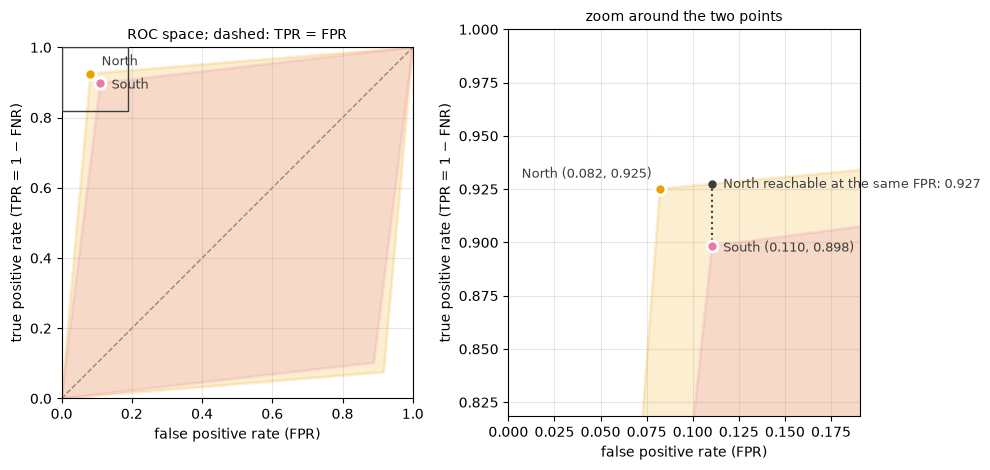

In [ ]:
from hiring_cv_bias.fairness.plots import plot_reachable_region

plot_reachable_region(effect)
plt.show()

The South's point (FPR 0.110, TPR 0.898) lies inside the North's quadrilateral: at the South's FPR the North could
reach a TPR of 0.927. So the South's quadrilateral is inside the North's, and the best rates the two regions can
share are the South's own. Equalizing the errors this way means bringing the North down to the South, with the
region in the decision, and no southern decision gets better.

The levers left are outside the parser and the matcher: the requirements of the job, since the lists where the
skills separate the candidates show no gap (3.6.3), and a human decision where the margin is too small to trust,
since Adecco's score already leaves three southern pairs in ten to a draw (3.6.1). Whether either counts as a
mitigation, and whether to develop them, is the question we put to the course.

**Limits.** The gap at equal margin (3.6.2) only just excludes 0. The class where the skills give everyone the same
value has only 501 southern pairs and a wide interval. The perturbation has no intervals: it is an average over 20 draws.

### Findings for RQ1

* **The parser's errors reach the selection.** Correcting them changes the score of about one pair in four and the
  outcome of 8.2% of the pairs. A new job title is the most common cause, and four in ten of the pairs that change
  outcome are candidates overtaken by a corrected competitor (3.1).
* **Independence is not violated.** No group is selected at a different rate from its reference group, with O or
  with C: every SPD interval contains 0 and every DI interval contains 1 (3.2). No group gains or loses places when the
  parser is corrected (3.3, 3.5).
* **Separation is violated for the South, and for women from the South in particular.** O has a higher false
  negative rate for southern pairs than for northern ones (10.9% against 8.0%) and a higher false positive rate (11.7%
  against 8.8%); the higher FNR holds with the top 3 too (3.5). Women from the South violate equalized odds through the
  FPR with the top half (4.2 points) and through the FNR with the top 3 (5.6, section 3.5). Their gaps have the same size as the
  South's, and within the South women and men differ little (FNR 3.1 against 2.4, FPR 4.2 against 1.2), so we read
  them as the South's effect rather than an additional one for women.
* **Sufficiency is violated for the South too.** Given the parser's decision, a southern pair is confirmed by the
  corrected profile less often than a northern one: 89.2% of O's selections against 92.0%, and 88.1% of its rejections
  against 91.2% (3.4); the lower PPV holds with the top 3 (3.5).
* **No gender gap.** Women and men have the same error rates (FNR 8.0% against 8.7%, FPR 9.0% against 9.4%) and
  predictive values (PPV 91.7% against 91.6%, NPV 91.4% against 90.3%) overall, every gap within its interval, and
  within each area: the gaps of women and men of the same area have overlapping
  intervals, which are wide for the smaller groups (the 6-point FNR difference in the Centre comes from the two
  smallest groups).
* **Why the South: the lists, not the readers.** The correction touches southern and northern pairs alike, but southern
  pairs stand closer to the cut (median margin 0.16 points against 0.35), because six southern lists in ten belong to
  a job that requires no skill (41.9% in the North), where the score cannot separate the candidates. With the North's
  margins the South's gap in error rate falls from 2.8 to 1.5 points; where the required skills separate the
  candidates it is 0.3 points, with an interval that holds 0. The same random noise on `Experience` flips more southern decisions, and only in the
  lists that cannot separate the candidates. Correcting the parser removes its own noise, not the fragile lists; the
  matcher is a known formula with nothing to train; equalized odds post-processing could only bring the North down
  to the South. The levers left are the job's requirements and a human decision on the pairs with a small margin
  (3.6).